<a href="https://colab.research.google.com/github/FunGrape/Labs_ML_Demchyshyn/blob/main/%D0%9B%D0%A04_%D0%94%D0%B5%D0%BC%D1%87%D0%B8%D1%88%D0%B8%D0%BD_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

!pip install kagglehub -q
import kagglehub
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

print("Розмір:", df.shape)
print(list(df.columns))
print(df.dtypes)
print("Цільова змінна: price")
df.describe()

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Розмір: (205, 26)
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
co

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Пропуски:\n", df.isna().sum()[lambda s: s > 0])
print("Повних дублікатів (без car_ID):", df.drop(columns="car_ID").duplicated().sum())
print(df.nunique().sort_values(ascending=False))

df["brand"] = df["CarName"].str.split().str[0].str.lower()
df["brand"] = df["brand"].replace({"maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
                                   "vokswagen": "volkswagen", "vw": "volkswagen"})
df = df.drop(columns="CarName")
print("Унікальних марок:", df["brand"].nunique())

Пропуски:
 Series([], dtype: int64)
Повних дублікатів (без car_ID): 0
car_ID              205
price               189
curbweight          171
CarName             147
carlength            75
horsepower           59
wheelbase            53
carheight            49
carwidth             44
enginesize           44
boreratio            38
stroke               37
compressionratio     32
highwaympg           30
citympg              29
peakrpm              23
fuelsystem            8
enginetype            7
cylindernumber        7
symboling             6
carbody               5
drivewheel            3
enginelocation        2
fueltype              2
aspiration            2
doornumber            2
dtype: int64
Унікальних марок: 22


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df["car_ID"].copy()
data = df.drop(columns="car_ID")

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


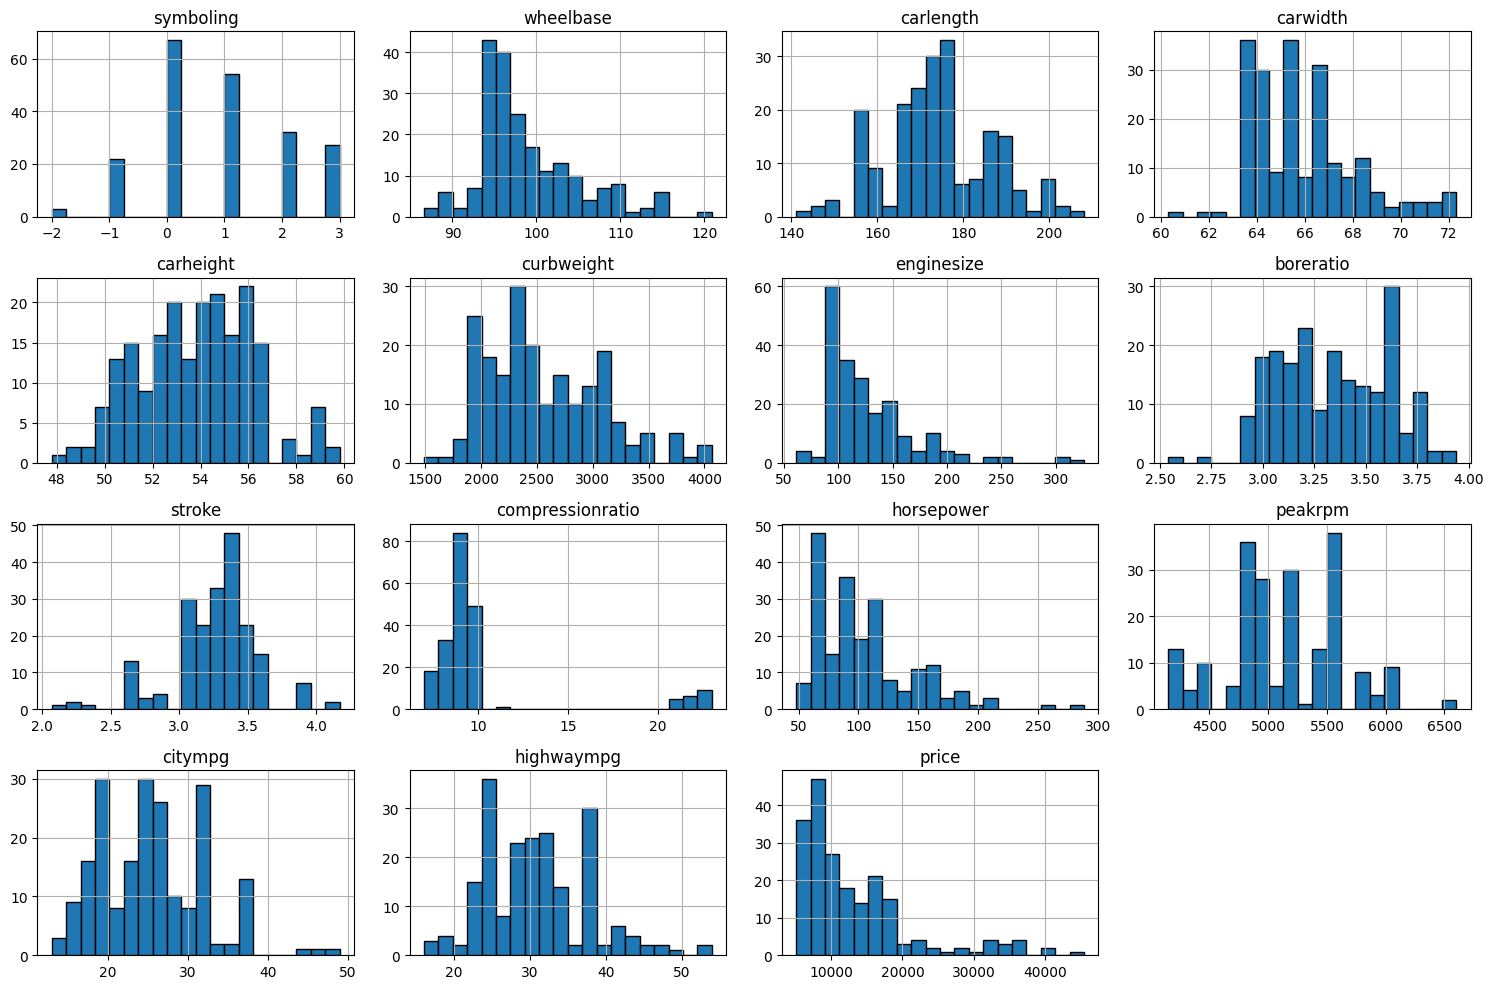

compressionratio    2.611
enginesize          1.948
price               1.778
horsepower          1.405
wheelbase           1.050
carwidth            0.904
curbweight          0.681
citympg             0.664
highwaympg          0.540
symboling           0.211
carlength           0.156
peakrpm             0.075
carheight           0.063
boreratio           0.020
stroke             -0.690
dtype: float64
Найбільш асиметричні ознаки: compressionratio, enginesize, price, horsepower, wheelbase


In [ ]:
num_cols_all = data.select_dtypes(include="number").columns.tolist()
data[num_cols_all].hist(bins=20, figsize=(15, 10), edgecolor="black")
plt.tight_layout()
plt.show()

skew_all = data[num_cols_all].skew().sort_values(ascending=False)
print(skew_all.round(3))
print("Найбільш асиметричні ознаки:", ", ".join(skew_all.abs().sort_values(ascending=False).head(5).index))

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop(columns="price")
y = data["price"]
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

disc_cols = ["symboling"]
cat_cols = X.select_dtypes(include="object").columns.tolist()
cont_cols = [c for c in X.select_dtypes(include="number").columns if c not in disc_cols]
print("Неперервні:", cont_cols)
print("Категоріальні:", cat_cols)

(164, 24) (41, 24)
Неперервні: ['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
Q1 = X_train[cont_cols].quantile(0.25)
Q3 = X_train[cont_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((X_train[cont_cols] < lower) | (X_train[cont_cols] > upper)).sum()
print("Кількість потенційних викидів (train):")
print(outliers[outliers > 0] if (outliers > 0).any() else "викидів немає")

X_train_c = X_train.copy()
X_test_c = X_test.copy()
X_train_c[cont_cols] = X_train[cont_cols].clip(lower=lower, upper=upper, axis=1)
X_test_c[cont_cols] = X_test[cont_cols].clip(lower=lower, upper=upper, axis=1)

Кількість потенційних викидів (train):
wheelbase            6
carwidth            10
enginesize           7
boreratio            1
stroke              16
compressionratio    20
horsepower           7
peakrpm              2
highwaympg           1
dtype: int64


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


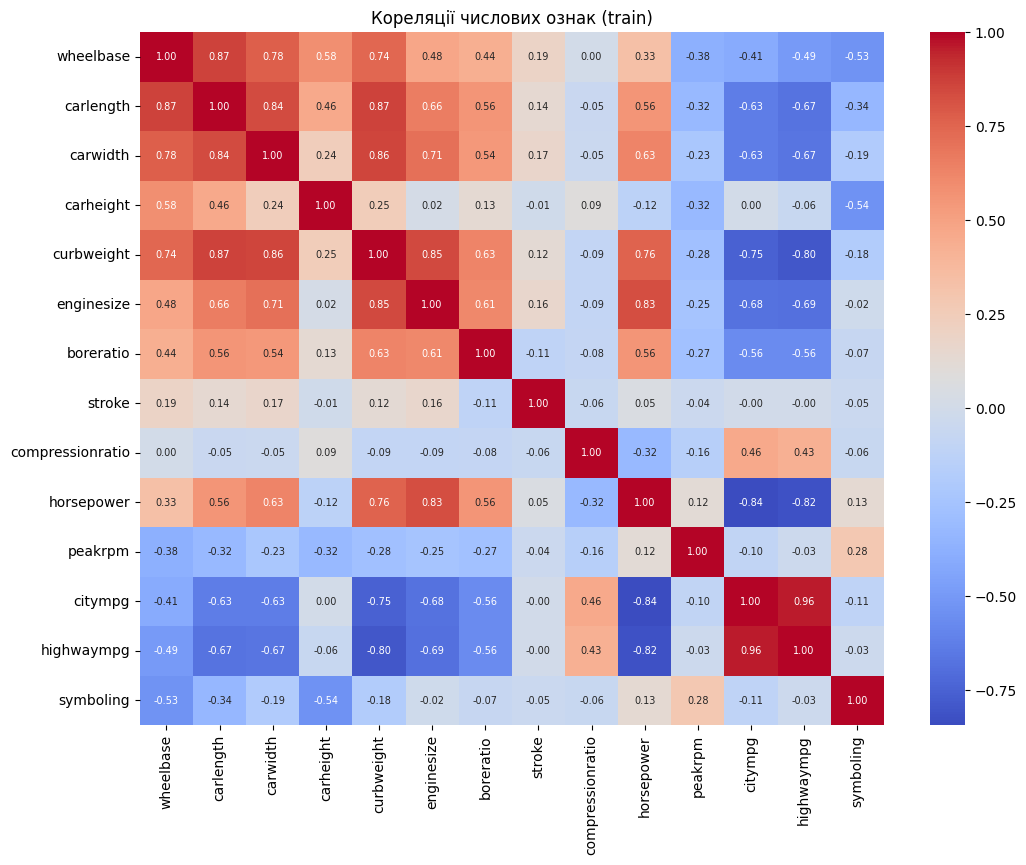

,Ознака 1,Ознака 2,r
3,citympg,highwaympg,0.963620
0,wheelbase,carlength,0.867043
1,carlength,curbweight,0.865988
2,carwidth,curbweight,0.858047


Ознаки, що видаляються: ['carlength', 'carwidth', 'citympg', 'wheelbase']


In [ ]:
num_all = cont_cols + disc_cols
corr = X_train_c[num_all].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Кореляції числових ознак (train)")
plt.show()

target_corr = X_train_c[num_all].corrwith(y_train).abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(num_all) for b in num_all[i + 1:]
         if abs(corr.loc[a, b]) > 0.85]
pairs_df = pd.DataFrame(pairs, columns=["Ознака 1", "Ознака 2", "r"]).sort_values("r", key=abs, ascending=False)
display(pairs_df)

to_drop = set()
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    if a in to_drop or b in to_drop:
        continue
    to_drop.add(a if target_corr[a] < target_corr[b] else b)
print("Ознаки, що видаляються:", sorted(to_drop))

X_train_s = X_train_c.drop(columns=list(to_drop))
X_test_s = X_test_c.drop(columns=list(to_drop))
cont_cols = [c for c in cont_cols if c not in to_drop]
disc_cols = [c for c in disc_cols if c not in to_drop]

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

cont_pipe = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler()),
])
preprocessor = ColumnTransformer([
    ("cont", cont_pipe, cont_cols),
    ("disc", StandardScaler(), disc_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
preprocessor.fit(X_train_s)
print("Розмір матриці після передобробки:", preprocessor.transform(X_train_s).shape)

Розмір матриці після передобробки: (164, 69)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
skew_before = X_train_s[cont_cols].skew()
transformed = preprocessor.named_transformers_["cont"].transform(X_train_s[cont_cols])
skew_after = pd.DataFrame(transformed, columns=cont_cols).skew()

skew_cmp = pd.DataFrame({"До": skew_before, "Після": skew_after})
skew_cmp["|До|-|Після|"] = skew_cmp["До"].abs() - skew_cmp["Після"].abs()
display(skew_cmp.round(3))
print("Середній |skew| до:", round(skew_before.abs().mean(), 3), "| після:", round(skew_after.abs().mean(), 3))

,До,Після,|До|-|Після|
carheight,0.028,-0.005,0.023
curbweight,0.712,0.050,0.663
enginesize,0.962,0.045,0.918
boreratio,0.063,-0.006,0.057
stroke,-0.398,0.016,0.382
compressionratio,0.056,0.005,0.051
horsepower,0.851,0.066,0.784
peakrpm,0.040,-0.004,0.036
highwaympg,0.244,-0.012,0.232


Середній |skew| до: 0.373 | після: 0.023


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": TransformedTargetRegressor(regressor=SVR(kernel="rbf", C=10), transformer=StandardScaler()),
}
models = {name: Pipeline([("preprocessor", clone(preprocessor)), ("model", reg)])
          for name, reg in regressors.items()}

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results, predictions = {}, {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    predictions[name] = pred
    results[name] = {
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, pred) * 100,
        "R2 (train)": r2_score(y_train, model.predict(X_train_s)),  # для аналізу перенавчання
    }
results_df = pd.DataFrame(results).T.sort_values("R2", ascending=False)
results_df.round(4)

,R2,MAE,MSE,"MAPE, %",R2 (train)
Random Forest,0.9547,1332.5062,3.578897e+06,9.7530,0.9847
Gradient Boosting,0.9304,1727.4037,5.492942e+06,12.0502,0.9932
SVR,0.9294,1668.3108,5.574315e+06,15.5397,0.9881
Linear Regression,0.8794,2156.0903,9.518255e+06,16.3764,0.9597
Lasso,0.8782,2105.2143,9.612671e+06,15.1336,0.9595
Ridge,0.8537,2368.4155,1.155081e+07,18.2026,0.9482


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування price є задачею регресії: цільова змінна неперервна, її значення можуть бути будь-яким числом з діапазону. Logistic Regression, попри назву, є моделлю класифікації: вона оцінює ймовірність віднесення об'єкта до одного з дискретних класів і повертає мітку класу, а не число. Для неперервної ціни вона непридатна: довелося б штучно розбивати ціну на інтервали й втрачати точність. Використані в роботі моделі (Linear, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) є регресійними й напряму прогнозують числове значення ціни.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


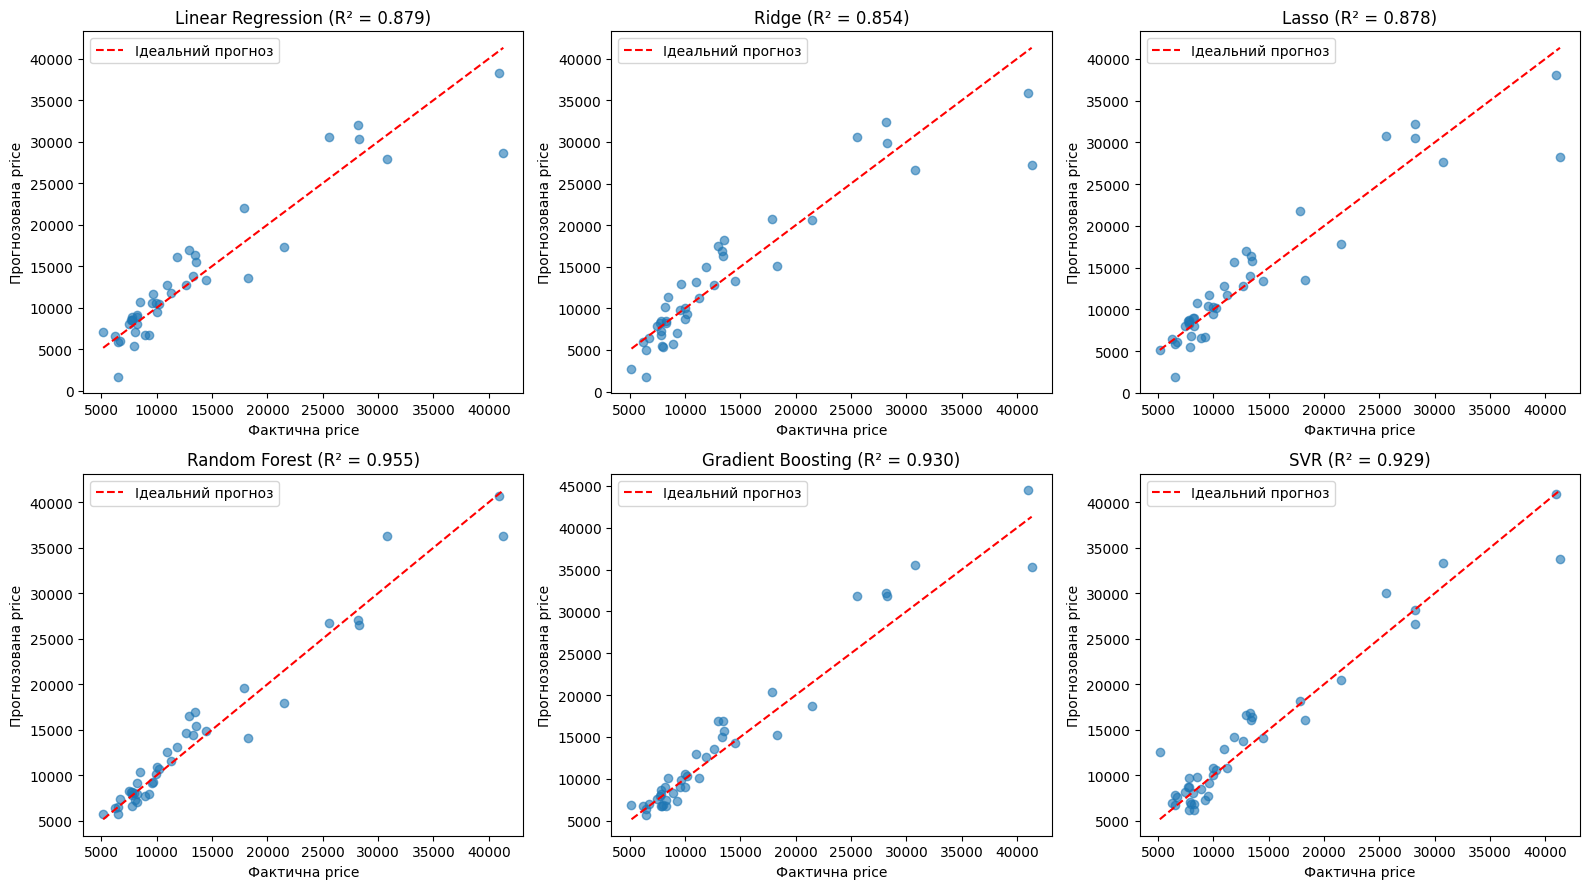

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
lims = [y_test.min(), y_test.max()]
for ax, (name, pred) in zip(axes.flatten(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot(lims, lims, "r--", label="Ідеальний прогноз")
    ax.set_title(f"{name} (R² = {results[name]['R2']:.3f})")
    ax.set_xlabel("Фактична price")
    ax.set_ylabel("Прогнозована price")
    ax.legend()
plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
sample_idx = X_test_s.sample(10, random_state=42).index
rf_pred = models["Random Forest"].predict(X_test_s.loc[sample_idx])

table = pd.DataFrame({
    "car_ID": id_test.loc[sample_idx].values,
    "Фактична ціна": y_test.loc[sample_idx].values,
    "Прогнозована ціна": rf_pred,
})
table["Абсолютна помилка"] = (table["Фактична ціна"] - table["Прогнозована ціна"]).abs()
table["Абсолютна відсоткова помилка, %"] = table["Абсолютна помилка"] / table["Фактична ціна"] * 100
table.round(2)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,26,6692.0,7337.12,645.12,9.64
1,176,9988.0,10916.38,928.38,9.29
2,148,10198.0,10644.75,446.75,4.38
3,17,41315.0,36252.35,5062.65,12.25
4,69,28248.0,26539.40,1708.60,6.05
5,147,7463.0,8213.76,750.76,10.06
6,144,9960.0,10105.13,145.13,1.46
7,85,14489.0,14849.57,360.57,2.49
8,195,12940.0,16552.34,3612.33,27.92
9,160,7788.0,7777.92,10.09,0.13


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


1. Первинний аналіз та якість даних
- Датасет містить 205 об'єктів та 26 ознак. У ході перевірки не виявлено пропущених значень та повних дублікатів (з урахуванням ідентифікатора car_ID).Ідентифікатор car_ID було відокремлено від матриці ознак, щоб запобігти витоку даних та спотворенню моделей. Назви марок автомобілів у стовпці CarName було стандартизовано та очищено від синтаксичних помилок (наприклад, maxda $\rightarrow$ mazda, vw $\rightarrow$ volkswagen).
2. Розподіли ознак та обробка викидів
- Аналіз асиметрії показав, що найбільш правоасиметричними ознаками є compressionratio (2.611), enginesize (1.948) та цільова змінна price (1.778).За допомогою методу міжквартильного розмаху (IQR) було виявлено потенційні викиди у низці неперервних ознак (найбільше в compressionratio, stroke, carwidth). Щоб уникнути втрати цінних даних на малих вибірках, замість видалення спостережень застосовано обмеження крайніх значень (capping/clipping) межами $[Q1 - 1.5 \cdot IQR, Q3 + 1.5 \cdot IQR]$, розрахованими виключно на навчальній вибірці ($X_{train}$).
3. Кореляційний аналіз та мультиколінеарність
- Побудова кореляційної матриці дозволила виявити високий рівень мультиколінеарності між деякими числовими ознаками ($\vert{}r\vert{} > 0.85$).Для запобігання дестабілізації лінійних моделей з пари сильно корельованих ознак залишалися ті, які мали вищий коефіцієнт кореляції з цільовою змінною price, тоді як інші були вилучені з подальшого аналізу.
4. Загальний підсумок: Виконана передобробка даних (очищення категорій, кліпінг викидів за IQR та видалення мультиколінеарних ознак) дозволила підготувати якісну матрицю ознак для подальшого побудови, регуляризації та порівняльного оцінювання регресійних моделей прогнозування вартості автомобіля.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
